# Détection de fraude — déséquilibre extrême et seuils métier

Ce notebook compare une régression logistique pondérée, une régression logistique entraînée après SMOTE, une Random Forest pondérée et XGBoost avec `scale_pos_weight`. Le jeu est très déséquilibré ; les scores de probabilité, les métriques précision-rappel et le volume de faux positifs sont donc étudiés ensemble.

**Découpage temporel :** le jeu est conservé dans son ordre `Time` : première période pour l'entraînement, suivante pour la validation (modèles et seuils), dernière pour le test final. Aucun suréchantillonnage n'est appliqué en validation ou en test. Les seuils de test ne sont jamais optimisés sur le test.

**Coûts :** les ratios de coût 1:1, 5:1, 10:1, 20:1 et 50:1 sont des scénarios illustratifs (coût d'un faux négatif : coût d'un faux positif). Ils ne sont pas des coûts monétaires observés. Le ratio 10:1 sert de référence provisoire pour l'évaluation finale ; le métier doit fournir les coûts réels avant toute décision opérationnelle.

In [1]:
from pathlib import Path
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbalancedPipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

ROOT_DIR = Path.cwd()
if not (ROOT_DIR / "data" / "raw").exists():
    ROOT_DIR = ROOT_DIR.parent
sys.path.insert(0, str(ROOT_DIR))

from src.evaluation.fraud import evaluate_fraud_threshold, select_cost_sensitive_threshold

DATA_PATH = ROOT_DIR / "data" / "raw" / "fraud" / "creditcard.csv"
REPORT_DIR = ROOT_DIR / "reports" / "generated"
MODEL_DIR = ROOT_DIR / "models"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42
REFERENCE_FN_COST = 10.0
REFERENCE_FP_COST = 1.0
COST_SCENARIOS = [1.0, 5.0, 10.0, 20.0, 50.0]
print(f"Jeu de données : {DATA_PATH}")

Jeu de données : /home/hawa-niass/Téléchargements/PLATEFORME INTELLIGENTE DE GESTION DES RISQUES BANCAIRES/data/raw/fraud/creditcard.csv


## 1. Contrôles et taux de fraude

`Time` est utilisé uniquement pour ordonner les périodes ; il ne sera pas fourni au classifieur afin de réduire le risque d'apprendre une dérive temporelle propre à ce petit jeu. `Amount` et les composantes `V1` à `V28` sont les variables explicatives.

In [2]:
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Jeu fraude introuvable : {DATA_PATH}")

fraud_data = pd.read_csv(DATA_PATH, low_memory=False)
required_columns = {"Time", "Amount", "Class"}
missing_columns = required_columns.difference(fraud_data.columns)
if missing_columns:
    raise ValueError(f"Colonnes requises absentes : {sorted(missing_columns)}")
if fraud_data["Time"].isna().any() or not fraud_data["Time"].is_monotonic_increasing:
    raise ValueError("Time doit être complet et trié pour le découpage chronologique.")
if fraud_data["Class"].isna().any() or not fraud_data["Class"].isin([0, 1]).all():
    raise ValueError("Class doit être une cible binaire sans valeur manquante.")

print(f"Forme : {fraud_data.shape}; doublons de lignes complets : {fraud_data.duplicated().sum():,}")
display(
    fraud_data["Class"].value_counts().rename(index={0: "Légitime", 1: "Fraude"})
    .to_frame("effectif")
    .assign(proportion=lambda table: table["effectif"] / len(fraud_data))
)
print(f"Valeurs manquantes : {fraud_data.isna().sum().sum():,}")
print(f"Prévalence fraude : {fraud_data['Class'].mean():.4%}")

Forme : (284807, 31); doublons de lignes complets : 1,081


,effectif,proportion
Class,,
Légitime,284315,0.998273
Fraude,492,0.001727


Valeurs manquantes : 0
Prévalence fraude : 0.1727%


In [3]:
time_60 = fraud_data["Time"].quantile(0.60)
time_80 = fraud_data["Time"].quantile(0.80)
train_mask = fraud_data["Time"].le(time_60)
validation_mask = fraud_data["Time"].gt(time_60) & fraud_data["Time"].le(time_80)
test_mask = fraud_data["Time"].gt(time_80)

train = fraud_data.loc[train_mask].copy()
validation = fraud_data.loc[validation_mask].copy()
test = fraud_data.loc[test_mask].copy()
split_summary = pd.DataFrame(
    {
        "période": ["Entraînement", "Validation", "Test final"],
        "lignes": [len(train), len(validation), len(test)],
        "fraudes": [int(train["Class"].sum()), int(validation["Class"].sum()), int(test["Class"].sum())],
        "prévalence_pct": [train["Class"].mean() * 100, validation["Class"].mean() * 100, test["Class"].mean() * 100],
        "time_min": [train["Time"].min(), validation["Time"].min(), test["Time"].min()],
        "time_max": [train["Time"].max(), validation["Time"].max(), test["Time"].max()],
    }
).set_index("période")
display(split_summary.round(4))
assert len(train) + len(validation) + len(test) == len(fraud_data)
assert train["Time"].max() <= validation["Time"].min()
assert validation["Time"].max() <= test["Time"].min()
assert train["Class"].nunique() == validation["Class"].nunique() == test["Class"].nunique() == 2

,lignes,fraudes,prévalence_pct,time_min,time_max
période,,,,,
Entraînement,170888,360,0.2107,0.0,120396.0
Validation,56957,57,0.1001,120397.0,145247.0
Test final,56962,75,0.1317,145248.0,172792.0


## 2. Modèles et traitement du déséquilibre

- Régression logistique avec `class_weight="balanced"` : baseline pondérée.
- Régression logistique avec SMOTE : le suréchantillonnage est placé dans un pipeline et ne s'applique qu'aux lignes d'entraînement, après imputation et standardisation.
- Random Forest avec pondération par bootstrap (`balanced_subsample`).
- XGBoost avec `scale_pos_weight` calculé uniquement sur l'entraînement.

SMOTE crée des exemples synthétiques dans l'espace des caractéristiques, pas de vraies transactions. Il peut augmenter le rappel tout en dégradant la précision ; on conserve donc les deux résultats et les faux positifs.

In [4]:
feature_columns = [column for column in fraud_data.columns if column not in {"Class", "Time"}]
X_train = train[feature_columns]
y_train = train["Class"].astype("int8")
X_validation = validation[feature_columns]
y_validation = validation["Class"].astype("int8")
X_test = test[feature_columns]
y_test = test["Class"].astype("int8")
positive_weight = (y_train.eq(0).sum() / y_train.eq(1).sum())
print(f"Variables utilisées : {len(feature_columns)}")
print(f"scale_pos_weight entraînement : {positive_weight:.2f}")

Variables utilisées : 29
scale_pos_weight entraînement : 473.69


In [5]:
models = {
    "Logistique pondérée": ImbalancedPipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("classifier", LogisticRegression(
                class_weight="balanced", max_iter=1000,
                solver="liblinear", random_state=RANDOM_STATE,
            )),
        ]
    ),
    "Logistique + SMOTE": ImbalancedPipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=5)),
            ("classifier", LogisticRegression(
                max_iter=1000, solver="liblinear", random_state=RANDOM_STATE,
            )),
        ]
    ),
    "Random Forest pondérée": ImbalancedPipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("classifier", RandomForestClassifier(
                n_estimators=160, max_depth=14, min_samples_leaf=5,
                class_weight="balanced_subsample", n_jobs=4,
                random_state=RANDOM_STATE,
            )),
        ]
    ),
    "XGBoost pondéré": ImbalancedPipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("classifier", XGBClassifier(
                n_estimators=350, max_depth=4, learning_rate=0.05,
                subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
                reg_lambda=2, scale_pos_weight=positive_weight,
                tree_method="hist", max_bin=128, eval_metric="aucpr",
                n_jobs=4, random_state=RANDOM_STATE, verbosity=0,
            )),
        ]
    ),
}

validation_scores = {}
validation_metrics = []
for model_name, pipeline in models.items():
    print(f"Entraînement : {model_name}")
    pipeline.fit(X_train, y_train)
    scores = pipeline.predict_proba(X_validation)[:, 1]
    validation_scores[model_name] = scores
    validation_metrics.append(
        {
            "modèle": model_name,
            "ROC_AUC_validation": roc_auc_score(y_validation, scores),
            "PR_AUC_AP_validation": average_precision_score(y_validation, scores),
        }
    )

validation_comparison = pd.DataFrame(validation_metrics).set_index("modèle").sort_values(
    "PR_AUC_AP_validation", ascending=False
)
display(validation_comparison.round(5))

Entraînement : Logistique pondérée
Entraînement : Logistique + SMOTE
Entraînement : Random Forest pondérée
Entraînement : XGBoost pondéré


,ROC_AUC_validation,PR_AUC_AP_validation
modèle,,
XGBoost pondéré,0.97834,0.77894
Logistique + SMOTE,0.96440,0.77382
Random Forest pondérée,0.97140,0.77302
Logistique pondérée,0.97091,0.77231


## 3. Seuils et scénarios de coûts

Pour chaque modèle et chaque ratio, on choisit le seuil qui minimise `FN × coût_FN + FP × coût_FP` sur la validation seulement. Un coût de faux négatif élevé tend à abaisser le seuil et augmente généralement les alertes ; le compromis est explicité par les nombres FP et FN. Les ratios sont pédagogiques tant que le coût de revue et la perte par fraude ne sont pas fournis par les métiers.

In [6]:
threshold_rows = []
selected_thresholds = {}
for model_name, scores in validation_scores.items():
    for fn_cost in COST_SCENARIOS:
        decision = select_cost_sensitive_threshold(
            y_validation,
            scores,
            false_negative_cost=fn_cost,
            false_positive_cost=REFERENCE_FP_COST,
        )
        threshold_rows.append(
            {
                "modèle": model_name,
                "coût_FN_par_coût_FP": fn_cost,
                **decision,
            }
        )
        if fn_cost == REFERENCE_FN_COST:
            selected_thresholds[model_name] = decision["threshold"]

threshold_analysis = pd.DataFrame(threshold_rows)
display(threshold_analysis.round(5))
threshold_analysis.to_csv(REPORT_DIR / "fraud_cost_scenarios_validation.csv", index=False)
validation_comparison.to_csv(REPORT_DIR / "fraud_model_comparison_validation.csv")
print(f"Ratio de référence provisoire : coût_FN:coût_FP = {REFERENCE_FN_COST:g}:1")

,modèle,coût_FN_par_coût_FP,threshold,validation_cost,false_positives,false_negatives,true_positives,true_negatives
0,Logistique pondérée,1.0,1.00000,21.0,2,19,38,56898
1,Logistique pondérée,5.0,0.99998,85.0,5,16,41,56895
2,Logistique pondérée,10.0,0.99958,155.0,25,13,44,56875
3,Logistique pondérée,20.0,0.99958,285.0,25,13,44,56875
4,Logistique pondérée,50.0,0.98865,652.0,52,12,45,56848
5,Logistique + SMOTE,1.0,1.00000,18.0,1,17,40,56899
6,Logistique + SMOTE,5.0,1.00000,86.0,1,17,40,56899
7,Logistique + SMOTE,10.0,0.99967,153.0,23,13,44,56877
8,Logistique + SMOTE,20.0,0.99967,283.0,23,13,44,56877
9,Logistique + SMOTE,50.0,0.98984,646.0,46,12,45,56854


Ratio de référence provisoire : coût_FN:coût_FP = 10:1


## 4. Test final et analyse des erreurs

Le modèle est choisi par PR-AUC/AP de validation. Le test temporel final n'intervient ni dans le choix du modèle, ni dans la sélection des seuils. Il sert une seule fois à rapporter les performances du modèle sélectionné au seuil issu du scénario de référence 10:1.

In [7]:
best_model_name = validation_comparison.index[0]
best_model = models[best_model_name]
best_threshold = selected_thresholds[best_model_name]
test_scores = best_model.predict_proba(X_test)[:, 1]
test_decisions = evaluate_fraud_threshold(
    y_test,
    test_scores,
    threshold=best_threshold,
)
test_cost = (
    test_decisions["false_negatives"] * REFERENCE_FN_COST
    + test_decisions["false_positives"] * REFERENCE_FP_COST
)
final_metrics = pd.DataFrame(
    [
        {
            "modèle choisi sur validation": best_model_name,
            "ROC_AUC_test": roc_auc_score(y_test, test_scores),
            "PR_AUC_AP_test": average_precision_score(y_test, test_scores),
            "seuil issu validation (coûts 10:1)": best_threshold,
            **test_decisions,
            "coût relatif test (FN*10 + FP*1)": test_cost,
        }
    ]
)
display(final_metrics.T.rename(columns={0: "valeur"}))
final_metrics.to_csv(REPORT_DIR / "fraud_final_test_metrics.csv", index=False)
joblib.dump(best_model, MODEL_DIR / "fraud_best_pipeline.joblib", compress=3)
print(f"Modèle sélectionné sur la validation : {best_model_name}")
print("Seuil fixé avant le test :", best_threshold)

,valeur
modèle choisi sur validation,XGBoost pondéré
ROC_AUC_test,0.974628
PR_AUC_AP_test,0.797184
seuil issu validation (coûts 10:1),0.772606
threshold,0.772606
true_negatives,56875
false_positives,12
false_negatives,18
true_positives,57
precision,0.826087


Modèle sélectionné sur la validation : XGBoost pondéré
Seuil fixé avant le test : 0.7726064920425415


,type,nombre,montant_total_des_transactions,montant_médian
0,Faux positifs — revue inutile,12,27138.27,1.50
1,Faux négatifs — fraudes manquées,18,2638.27,10.16
2,Vrais positifs — fraudes détectées,57,5090.99,1.59


Le montant du jeu est utilisé comme indicateur descriptif d'exposition, pas comme perte nette récupérable ni comme coût monétaire calibré.


,Time,Amount,Class,probability_fraud,prediction,error_type
274468,166023.0,2.00,0,0.9981,1,FP
266590,162400.0,0.77,0,0.9937,1,FP
267760,162916.0,0.77,0,0.9934,1,FP
276061,166878.0,0.77,0,0.9913,1,FP
228505,145538.0,0.77,0,0.9808,1,FP
266434,162332.0,0.77,0,0.9408,1,FP
277772,167846.0,1.99,0,0.9089,1,FP
277737,167826.0,1.00,0,0.9089,1,FP
274771,166198.0,25691.16,0,0.8850,1,FP
277877,167912.0,1.99,0,0.8484,1,FP


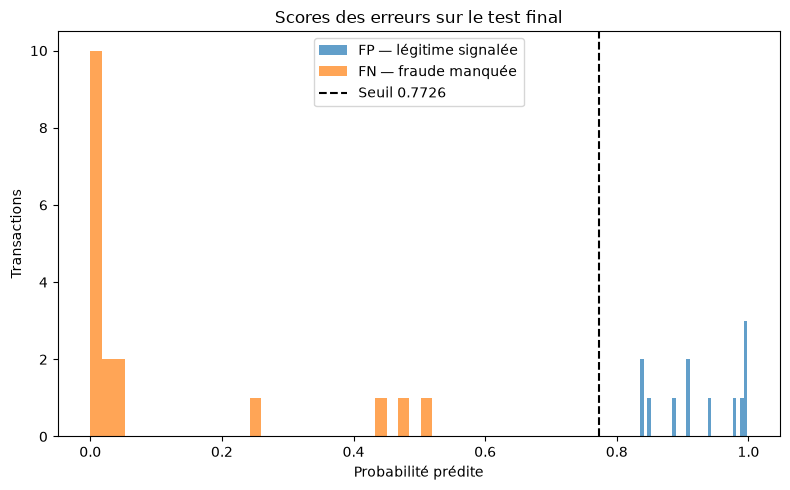

In [8]:
test_review = test[["Time", "Amount", "Class"]].copy()
test_review["probability_fraud"] = test_scores
test_review["prediction"] = (test_scores >= best_threshold).astype("int8")
false_positives = test_review.loc[test_review["Class"].eq(0) & test_review["prediction"].eq(1)].copy()
false_negatives = test_review.loc[test_review["Class"].eq(1) & test_review["prediction"].eq(0)].copy()
true_positives = test_review.loc[test_review["Class"].eq(1) & test_review["prediction"].eq(1)].copy()

error_summary = pd.DataFrame(
    [
        {
            "type": "Faux positifs — revue inutile",
            "nombre": len(false_positives),
            "montant_total_des_transactions": false_positives["Amount"].sum(),
            "montant_médian": false_positives["Amount"].median(),
        },
        {
            "type": "Faux négatifs — fraudes manquées",
            "nombre": len(false_negatives),
            "montant_total_des_transactions": false_negatives["Amount"].sum(),
            "montant_médian": false_negatives["Amount"].median(),
        },
        {
            "type": "Vrais positifs — fraudes détectées",
            "nombre": len(true_positives),
            "montant_total_des_transactions": true_positives["Amount"].sum(),
            "montant_médian": true_positives["Amount"].median(),
        },
    ]
)
display(error_summary.round(2))
print(
    "Le montant du jeu est utilisé comme indicateur descriptif d'exposition, "
    "pas comme perte nette récupérable ni comme coût monétaire calibré."
)

error_examples = pd.concat(
    [
        false_positives.assign(error_type="FP"),
        false_negatives.assign(error_type="FN"),
    ]
).sort_values("probability_fraud", ascending=False)
display(error_examples.head(20).round(4))
error_summary.to_csv(REPORT_DIR / "fraud_error_analysis_test.csv", index=False)
error_examples.to_csv(REPORT_DIR / "fraud_error_examples_test.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(false_positives["probability_fraud"], bins=30, alpha=0.7, label="FP — légitime signalée")
ax.hist(false_negatives["probability_fraud"], bins=30, alpha=0.7, label="FN — fraude manquée")
ax.axvline(best_threshold, linestyle="--", color="black", label=f"Seuil {best_threshold:.4f}")
ax.set(title="Scores des erreurs sur le test final", xlabel="Probabilité prédite", ylabel="Transactions")
ax.legend()
plt.tight_layout()
plt.show()

## Lecture métier et limites

- Un faux positif provoque une alerte ou une revue inutile ; son coût dépend du dispositif opérationnel.
- Un faux négatif est une fraude non signalée ; `Amount` donne une exposition brute, mais ne mesure ni la perte nette ni le montant récupérable.
- Les seuils optimisés dépendent directement du ratio de coûts et du niveau de fraude de la période. Les scénarios doivent être remplacés par des coûts documentés par les équipes métier.
- Le découpage temporel est plus réaliste qu'un découpage aléatoire, mais ce jeu anonymisé ne contient pas l'identité client ni les coûts de revue. Les résultats restent pédagogiques et la période de test ne représente pas nécessairement le futur.
- SMOTE et les pondérations modifient l'apprentissage ; les probabilités peuvent être mal calibrées. En production, évaluer la calibration et surveiller la dérive avant de déployer.